In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from explainability import MultimodalGradCAM, TelemetryFeatureAttributor

print("Modules imported successfully!")

Modules imported successfully!


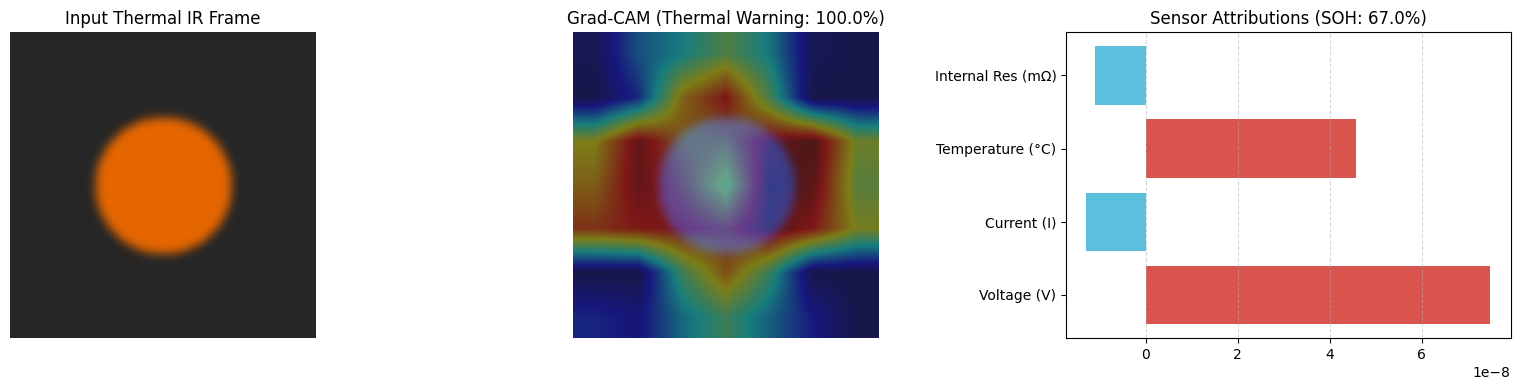

In [4]:
import sys
if "explainability" in sys.modules:
    del sys.modules["explainability"]

import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from explainability import MultimodalGradCAM, TelemetryFeatureAttributor

# 1. Load trained model and explainability engines
MODEL_PATH = os.path.join("models", "battery_multimodal_model.keras")
model = tf.keras.models.load_model(MODEL_PATH)
gradcam = MultimodalGradCAM(model=model, last_conv_layer_name="Conv_1")
attributor = TelemetryFeatureAttributor(model=model)
CLASS_NAMES = ["Safe", "Thermal Warning", "Thermal Runaway Critical"]

# 2. Testing Function
def test_battery_prediction(image_path=None, custom_telemetry=None):
    # A. Thermal IR image frame
    if image_path and os.path.exists(image_path):
        img = cv2.imread(image_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = cv2.resize(img, (224, 224)) / 255.0
    else:
        # Generate test frame with a simulated hot-spot
        img = np.ones((224, 224, 3), dtype=np.float32) * 0.15
        cv2.circle(img, (112, 112), 50, (0.9, 0.4, 0.0), -1)
        img = cv2.GaussianBlur(img, (21, 21), 0)

    # B. Telemetry sequence (30 timesteps x 4 features: [V, I, T, R])
    if custom_telemetry is not None:
        tel = np.array(custom_telemetry, dtype=np.float32)
    else:
        v = np.linspace(0.8, 0.6, 30)
        i = np.linspace(0.4, 0.7, 30)
        t = np.linspace(0.3, 0.85, 30)
        r = np.linspace(0.2, 0.45, 30)
        tel = np.stack([v, i, t, r], axis=-1)

    img_tensor = tf.convert_to_tensor(img[np.newaxis, ...], dtype=tf.float32)
    tel_tensor = tf.convert_to_tensor(tel[np.newaxis, ...], dtype=tf.float32)

    # C. Forward Inference
    soh_pred, risk_pred = model({"thermal_image_input": img_tensor, "telemetry_seq_input": tel_tensor})
    pred_risk_idx = int(np.argmax(risk_pred[0]))
    confidence = float(risk_pred[0][pred_risk_idx]) * 100.0
    soh_percent = float(soh_pred[0][0]) * 100.0

    # D. Explainability Outputs
    heatmap, _ = gradcam.generate_heatmap(img_tensor, tel_tensor, target_class_idx=pred_risk_idx)
    overlay, _ = gradcam.overlay_heatmap(heatmap, img)
    attributions = attributor.compute_attributions(img_tensor, tel_tensor, target_class_idx=pred_risk_idx)

    # E. Render Visual Evaluation
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    
    axes[0].imshow(img)
    axes[0].set_title("Input Thermal IR Frame")
    axes[0].axis("off")

    axes[1].imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
    axes[1].set_title(f"Grad-CAM ({CLASS_NAMES[pred_risk_idx]}: {confidence:.1f}%)")
    axes[1].axis("off")

    feats = list(attributions.keys())
    scores = list(attributions.values())
    colors = ["#d9534f" if s > 0 else "#5bc0de" for s in scores]
    axes[2].barh(feats, scores, color=colors)
    axes[2].set_title(f"Sensor Attributions (SOH: {soh_percent:.1f}%)")
    axes[2].grid(axis="x", linestyle="--", alpha=0.5)

    plt.tight_layout()
    plt.show()

# 3. Execute
test_battery_prediction()

In [5]:
import os
import cv2
import json
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from explainability import MultimodalGradCAM, TelemetryFeatureAttributor

# 1. Load artifacts
MODEL_PATH = os.path.join("models", "battery_multimodal_model.keras")
model = tf.keras.models.load_model(MODEL_PATH)
gradcam = MultimodalGradCAM(model=model, last_conv_layer_name="Conv_1")
attributor = TelemetryFeatureAttributor(model=model)
CLASS_NAMES = ["Safe", "Thermal Warning", "Thermal Runaway Critical"]

# 2. Interactive user-input evaluation function
def evaluate_user_sample(
    image_input=None,          # File path string OR numpy array (224, 224, 3)
    telemetry_input=None,      # Path to .csv/.json OR numpy array (30, 4)
    target_class_id=None       # Optional: force XAI target class index (0, 1, or 2)
):
    """
    Evaluates arbitrary unseen battery inputs and generates complete XAI diagnostics.
    """
    # --- A. Ingest Image ---
    if isinstance(image_input, str) and os.path.exists(image_input):
        print(f"Loading user image from file: {image_input}")
        raw_bgr = cv2.imread(image_input)
        raw_rgb = cv2.cvtColor(raw_bgr, cv2.COLOR_BGR2RGB)
        img = cv2.resize(raw_rgb, (224, 224)).astype(np.float32) / 255.0
    elif isinstance(image_input, np.ndarray):
        print("Using provided custom image array...")
        img = cv2.resize(image_input, (224, 224)).astype(np.float32)
        if img.max() > 1.0:
            img /= 255.0
    else:
        print("No image provided. Synthesizing test infrared matrix with hot-spot...")
        img = np.ones((224, 224, 3), dtype=np.float32) * 0.15
        cv2.circle(img, (112, 112), 48, (0.95, 0.35, 0.05), -1)
        img = cv2.GaussianBlur(img, (21, 21), 0)

    # --- B. Ingest Telemetry ---
    if isinstance(telemetry_input, str) and os.path.exists(telemetry_input):
        print(f"Loading user telemetry from file: {telemetry_input}")
        if telemetry_input.endswith(".csv"):
            tel_raw = np.loadtxt(telemetry_input, delimiter=",", skiprows=1)
        elif telemetry_input.endswith(".json"):
            with open(telemetry_input, "r") as f:
                tel_raw = np.array(json.load(f), dtype=np.float32)
        else:
            raise ValueError("Supported file formats are .csv and .json")
        tel = tel_raw[-30:, :4].astype(np.float32)
    elif isinstance(telemetry_input, (list, np.ndarray)):
        print("Using provided custom telemetry sequence...")
        tel = np.array(telemetry_input, dtype=np.float32)
        if tel.shape != (30, 4):
            raise ValueError(f"Telemetry array must have shape (30, 4), received {tel.shape}")
    else:
        print("No telemetry provided. Simulating default thermal warning sequence...")
        v = np.linspace(0.85, 0.58, 30)
        i = np.linspace(0.40, 0.75, 30)
        t = np.linspace(0.30, 0.90, 30)
        r = np.linspace(0.20, 0.50, 30)
        tel = np.stack([v, i, t, r], axis=-1).astype(np.float32)

    # --- C. Run Forward Inference ---
    img_tensor = tf.convert_to_tensor(img[np.newaxis, ...], dtype=tf.float32)
    tel_tensor = tf.convert_to_tensor(tel[np.newaxis, ...], dtype=tf.float32)

    soh_pred, risk_pred = model({"thermal_image_input": img_tensor, "telemetry_seq_input": tel_tensor})
    risk_scores = risk_pred[0].numpy()
    pred_risk_idx = int(np.argmax(risk_scores)) if target_class_id is None else target_class_id
    confidence = float(risk_scores[pred_risk_idx]) * 100.0
    soh_percent = float(soh_pred[0][0]) * 100.0

    # --- D. Compute XAI Subsystems ---
    heatmap, _ = gradcam.generate_heatmap(img_tensor, tel_tensor, target_class_idx=pred_risk_idx)
    overlay, _ = gradcam.overlay_heatmap(heatmap, img)
    attributions = attributor.compute_attributions(img_tensor, tel_tensor, target_class_idx=pred_risk_idx)

    # --- E. Console Diagnostic Output ---
    print("\n" + "="*50)
    print("           MODEL PREDICTION SUMMARY")
    print("="*50)
    print(f" Estimated Battery SOH    : {soh_percent:.2f}%")
    print(f" Hazard State Assessment : {CLASS_NAMES[pred_risk_idx].upper()}")
    print(f" Prediction Confidence    : {confidence:.2f}%")
    print(" Class Distribution:")
    for idx, c_name in enumerate(CLASS_NAMES):
        print(f"   - {c_name:<25}: {risk_scores[idx]*100:.2f}%")
    print("="*50)

    # --- F. Render Multi-Panel Visualizations ---
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

    axes[0].imshow(img)
    axes[0].set_title("1. Input Thermal IR Frame", fontsize=11, fontweight="bold")
    axes[0].axis("off")

    axes[1].imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
    axes[1].set_title(f"2. Grad-CAM Overlay\n({CLASS_NAMES[pred_risk_idx]}: {confidence:.1f}%)", fontsize=11, fontweight="bold")
    axes[1].axis("off")

    feats = list(attributions.keys())
    scores = list(attributions.values())
    bar_colors = ["#d9534f" if s > 0 else "#5bc0de" for s in scores]
    axes[2].barh(feats, scores, color=bar_colors)
    axes[2].set_title(f"3. Temporal Feature Attribution\n(Estimated SOH: {soh_percent:.1f}%)", fontsize=11, fontweight="bold")
    axes[2].set_xlabel("Attribution Magnitude (Impact on Hazard)")
    axes[2].grid(axis="x", linestyle="--", alpha=0.6)

    plt.tight_layout()
    plt.show()

    return {
        "soh_percent": round(soh_percent, 2),
        "predicted_risk": CLASS_NAMES[pred_risk_idx],
        "confidence": round(confidence, 2),
        "sensor_attributions": attributions
    }

print("Interactive evaluation testbench initialized successfully!")

Interactive evaluation testbench initialized successfully!


No image provided. Synthesizing test infrared matrix with hot-spot...
No telemetry provided. Simulating default thermal warning sequence...

           MODEL PREDICTION SUMMARY
 Estimated Battery SOH    : 66.16%
 Hazard State Assessment : THERMAL WARNING
 Prediction Confidence    : 99.99%
 Class Distribution:
   - Safe                     : 0.01%
   - Thermal Warning          : 99.99%
   - Thermal Runaway Critical : 0.00%


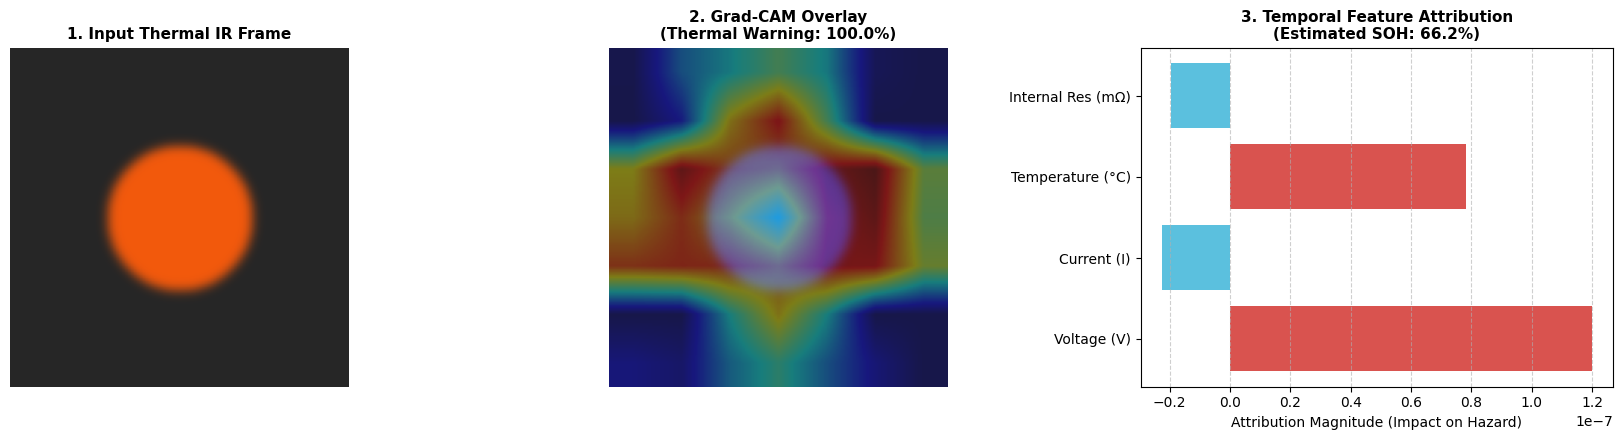

In [6]:
results = evaluate_user_sample()

No image provided. Synthesizing test infrared matrix with hot-spot...
Using provided custom telemetry sequence...

           MODEL PREDICTION SUMMARY
 Estimated Battery SOH    : 66.11%
 Hazard State Assessment : THERMAL WARNING
 Prediction Confidence    : 99.99%
 Class Distribution:
   - Safe                     : 0.01%
   - Thermal Warning          : 99.99%
   - Thermal Runaway Critical : 0.00%


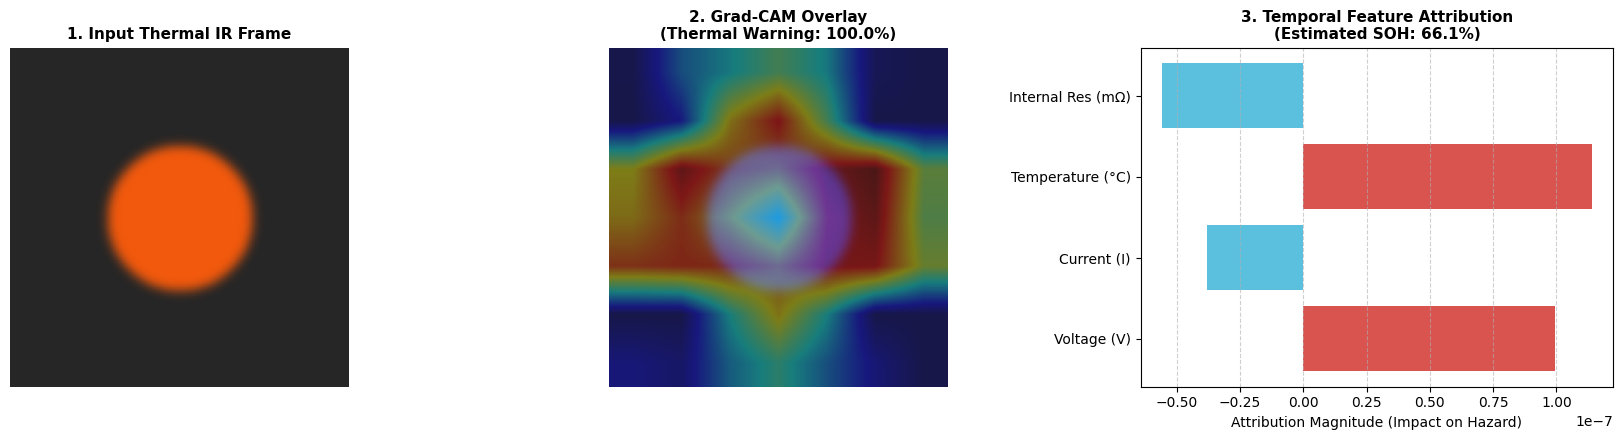

In [7]:
# Unseen high-stress scenario:
v_drop = np.linspace(0.85, 0.25, 30)         # Rapid cell voltage collapse
i_surge = np.linspace(0.40, 0.95, 30)        # Short-circuit current draw
t_spike = np.linspace(0.50, 0.99, 30)        # Extreme temperature spike
r_rise = np.linspace(0.30, 0.90, 30)         # Spiking internal resistance

critical_profile = np.stack([v_drop, i_surge, t_spike, r_rise], axis=-1)

results_critical = evaluate_user_sample(telemetry_input=critical_profile)